# Ablación de las cabezas de la red funcional
Comparación de las cabezas lineal, MLP y KAN con los modelos entrenados en `funciones/Entrenamiento_red.py` (objetivo directo): mismo codificador, mismo decodificador FPCA, parámetros de KAN y MLP igualados (diferencia ≤ 10 %), 3 semillas por cabeza y el mismo presupuesto de entrenamiento. Las funciones están en `funciones/Ablacion_cabezas.py`.

Evaluación en validación: estaciones de validación en 1996–2000, que no están en entrenamiento. Las estaciones de prueba (2001–2003) no se usan.

## Configuración y datos

In [1]:
import sys
sys.path.append('funciones')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import Ablacion_arquitectura as Aa
import Ablacion_cabezas as Ac

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
D = Aa.preparar_datos()
print('Curvas de validación:', D['va'].sum(), '| estaciones:', D['meta'].STATION_ID[D['va']].nunique())
display(pd.read_csv('Tablas/08_red_configuracion_elegida.csv'))
pd.read_csv('Tablas/08_red_parametros_cabezas.csv')

Curvas de validación: 102 | estaciones: 25


,cabeza,q,M,lambda,mean,std
0,KAN,8,5,1000.0,111.181515,16.135870
1,MLP,8,5,10000.0,91.959483,1.366159
2,lineal,8,5,100.0,122.917834,1.518012


,q,M,parametros_lineal,parametros_KAN,ocultas_MLP,parametros_MLP,diferencia_pct
0,6,5,45,442,31,439,0.678733
1,7,5,50,476,31,470,1.260504
2,8,5,55,510,32,517,1.372549


### Métricas
- **L2_relativo**: $\|\hat y - y\| / \|y\|$ frente a la curva de la estación (malla fina), promedio de las curvas.
- **KGE**: $1 - \sqrt{(r-1)^2 + (\alpha-1)^2 + (\beta-1)^2}$, mediana de las curvas.
- **sesgo_%**: sesgo del acumulado anual, diferencia porcentual entre el acumulado predicho y el observado en las péntadas observadas.
- **pico1_pentadas / pico2_pentadas**: error en la fecha del máximo de marzo–junio y de septiembre–diciembre.
- **RECM_mm**: raíz del error cuadrático medio frente a las péntadas observadas.

Cada cabeza se resume con la media y la desviación estándar de sus 3 semillas.

In [2]:
predicciones = Ac.predicciones_validacion(D)
por_curva = Ac.tablas_por_curva(D, predicciones)
tabla_metricas = Ac.tabla_metricas(por_curva)
tabla_metricas.to_csv('Tablas/09_ablacion_cabezas_metricas.csv')
tabla_metricas.round(3)

,L2_relativo,L2_relativo_desv,KGE,KGE_desv,sesgo_%,sesgo_%_desv,pico1_pentadas,pico1_pentadas_desv,pico2_pentadas,pico2_pentadas_desv,RECM_mm,RECM_mm_desv
modelo,,,,,,,,,,,,
lineal,0.432,0.008,0.439,0.01,-10.922,1.917,3.974,0.056,2.315,0.068,28.891,0.090
MLP,0.403,0.003,0.481,0.01,-5.669,0.503,4.296,0.228,2.319,0.065,27.102,0.127
KAN,0.432,0.006,0.433,0.04,-4.827,7.641,4.325,0.101,2.229,0.074,27.867,1.061
Satélite sin corregir,0.541,NaN,0.306,NaN,3.813,NaN,4.143,NaN,6.480,NaN,28.683,NaN


## Media y sesgo por péntada

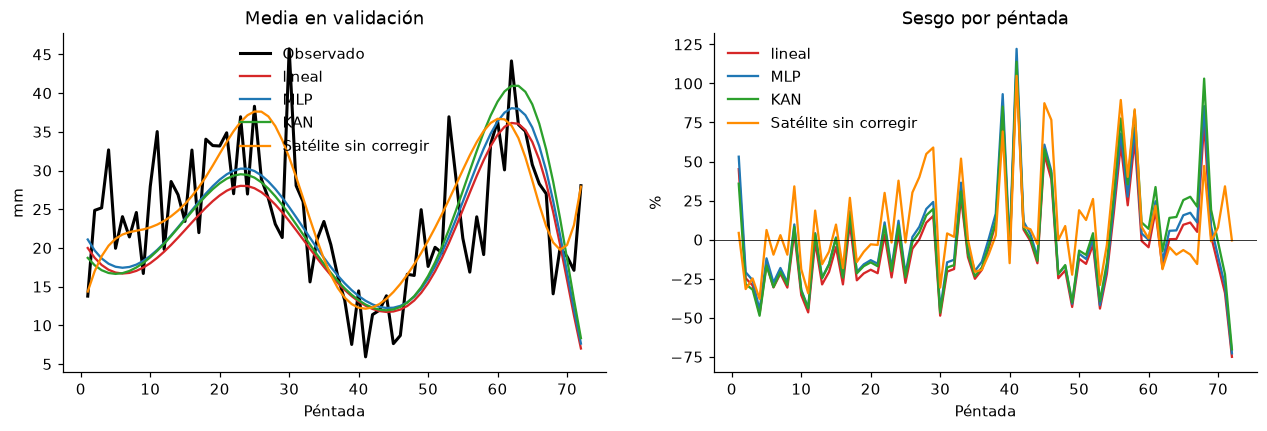

In [3]:
fig = Ac.grafica_media(D, predicciones); fig.savefig('Figuras/09_ablacion_cabezas_media_sesgo.png', dpi=150, bbox_inches='tight'); plt.show()

## Bootstrap por estaciones
Se remuestrean las estaciones de validación con reemplazo (2000 remuestreos) y cada estación aporta todas sus curvas. En cada remuestreo se calcula la métrica de cada cabeza (promedio de sus 3 semillas) y la diferencia entre cabezas. El IC del 95 % es el intervalo entre los percentiles 2,5 y 97,5 de las diferencias.

Una cabeza supera a otra solo si el IC del 95 % de la diferencia excluye el cero. En el sesgo se compara el valor absoluto.

In [4]:
remuestreos = Ac.bootstrap(D, por_curva)
comparacion = Ac.comparar(por_curva, remuestreos)
comparacion.to_csv('Tablas/09_ablacion_cabezas_bootstrap.csv', index=False)
comparacion.round(3)

,A,B,metrica,diferencia_A_menos_B,IC95_inferior,IC95_superior,conclusion
0,MLP,lineal,L2_relativo,-0.029,-0.059,-0.006,MLP supera a lineal
1,MLP,lineal,KGE,0.041,-0.015,0.109,Sin diferencia
2,MLP,lineal,sesgo_abs_%,-5.253,-14.332,2.385,Sin diferencia
3,MLP,lineal,pico1_pentadas,0.323,-0.018,0.689,Sin diferencia
4,MLP,lineal,pico2_pentadas,0.005,-0.099,0.103,Sin diferencia
5,MLP,lineal,RECM_mm,-1.789,-4.611,-0.092,MLP supera a lineal
6,KAN,lineal,L2_relativo,-0.000,-0.038,0.033,Sin diferencia
7,KAN,lineal,KGE,-0.007,-0.050,0.063,Sin diferencia
8,KAN,lineal,sesgo_abs_%,-5.916,-14.438,4.230,Sin diferencia
9,KAN,lineal,pico1_pentadas,0.351,-0.090,0.880,Sin diferencia


In [5]:
comparacion.pivot_table(index=['A', 'B'], columns='metrica', values='conclusion', aggfunc='first')[list(Ac.METRICAS)]

metrica                                                 L2_relativo  \
A      B                                                              
KAN    MLP                                         MLP supera a KAN   
       Satélite sin corregir     KAN supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
MLP    Satélite sin corregir     MLP supera a Satélite sin corregir   
       lineal                                   MLP supera a lineal   
lineal Satélite sin corregir  lineal supera a Satélite sin corregir   

metrica                                                         KGE  \
A      B                                                              
KAN    MLP                                           Sin diferencia   
       Satélite sin corregir     KAN supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
MLP    Satélite sin corregir     MLP supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
lineal Satélite sin corregir  lineal supera a Satélite sin corregir   

metrica                          sesgo_abs_%  pico1_pentadas  \
A      B                                                       
KAN    MLP                    Sin diferencia  Sin diferencia   
       Satélite sin corregir  Sin diferencia  Sin diferencia   
       lineal                 Sin diferencia  Sin diferencia   
MLP    Satélite sin corregir  Sin diferencia  Sin diferencia   
       lineal                 Sin diferencia  Sin diferencia   
lineal Satélite sin corregir  Sin diferencia  Sin diferencia   

metrica                                              pico2_pentadas  \
A      B                                                              
KAN    MLP                                           Sin diferencia   
       Satélite sin corregir     KAN supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
MLP    Satélite sin corregir     MLP supera a Satélite sin corregir   
       lineal                                        Sin diferencia   
lineal Satélite sin corregir  lineal supera a Satélite sin corregir   

metrica                                                  RECM_mm  
A      B                                                          
KAN    MLP                                      MLP supera a KAN  
       Satélite sin corregir                      Sin diferencia  
       lineal                                     Sin diferencia  
MLP    Satélite sin corregir  MLP supera a Satélite sin corregir  
       lineal                                MLP supera a lineal  
lineal Satélite sin corregir                      Sin diferencia

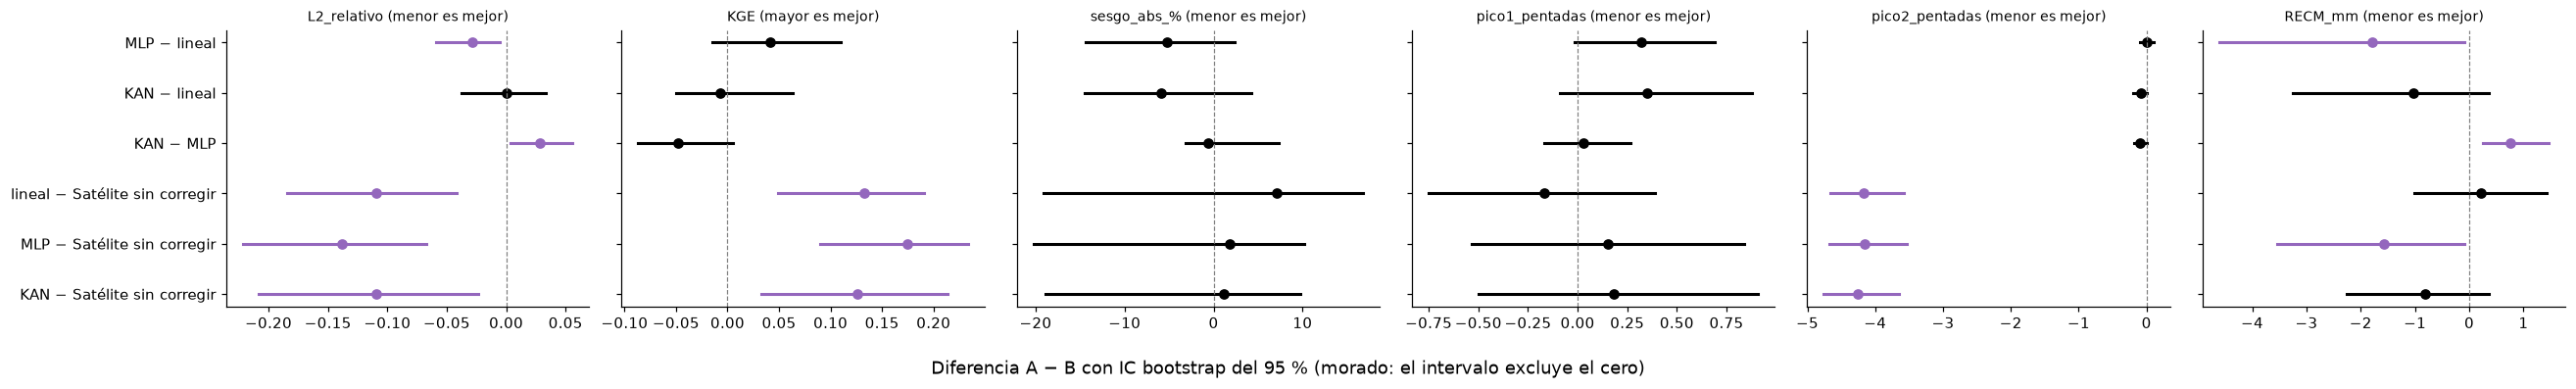

In [6]:
fig = Ac.grafica_intervalos(comparacion); fig.savefig('Figuras/09_ablacion_cabezas_bootstrap.png', dpi=150, bbox_inches='tight'); plt.show()